# Practical 3: Gradient Descent (GD) from Scratch - Anti-Money Laundering
**Course**: Machine Learning (B.Tech)
**Task**: Custom Batch Gradient Descent Optimization with MSE Loss Convergence Curve

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
X = df[['Amount Paid']].values
y = df['Amount Received'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).flatten()
X_test_scaled = scaler.transform(X_test).flatten()

# Batch Gradient Descent from Scratch
theta_0 = 0.0
theta_1 = 0.0
alpha = 0.01
epochs = 150
m = len(X_train_scaled)
loss_history = []

for epoch in range(epochs):
    y_pred = theta_0 + theta_1 * X_train_scaled
    loss = (1 / (2 * m)) * np.sum((y_pred - y_train) ** 2)
    loss_history.append(loss)
    
    d_theta_0 = (1 / m) * np.sum(y_pred - y_train)
    d_theta_1 = (1 / m) * np.sum((y_pred - y_train) * X_train_scaled)
    
    theta_0 -= alpha * d_theta_0
    theta_1 -= alpha * d_theta_1

print(f"Batch GD Final Parameters: theta_0 = {theta_0:.4f}, theta_1 = {theta_1:.4f}")
print(f"Final MSE Loss: {loss_history[-1]:.4f}")

Batch GD Final Parameters: theta_0 = 3529416.2943, theta_1 = 307513117.8266
Final MSE Loss: 4191343329582775.5000


## 2. Gradient Descent Cost Convergence Curve

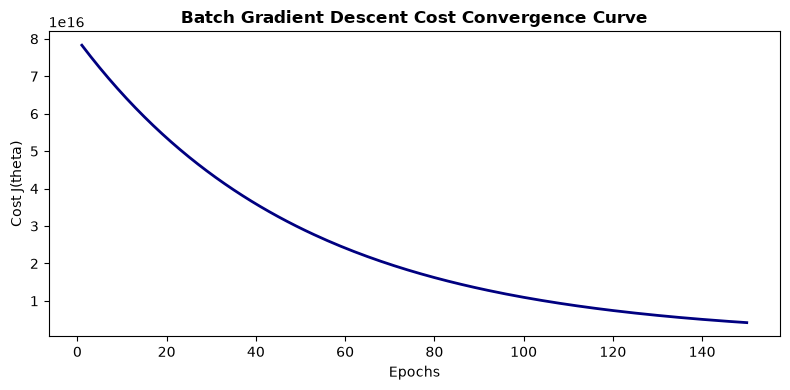

In [2]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), loss_history, color='navy', linewidth=2)
plt.title("Batch Gradient Descent Cost Convergence Curve", fontsize=12, fontweight='bold')
plt.xlabel("Epochs")
plt.ylabel("Cost J(theta)")
plt.tight_layout()
plt.show()

## 3. Comparison with Scikit-Learn Normal Equation

In [3]:
sk_model = LinearRegression()
sk_model.fit(X_train_scaled.reshape(-1, 1), y_train)

y_pred_gd = theta_0 + theta_1 * X_test_scaled
rmse_gd = np.sqrt(mean_squared_error(y_test, y_pred_gd))
rmse_sk = np.sqrt(mean_squared_error(y_test, sk_model.predict(X_test_scaled.reshape(-1, 1))))

comp = pd.DataFrame({
    'Method': ['Batch Gradient Descent (From Scratch)', 'Scikit-Learn Normal Equation'],
    'theta_0 (Intercept)': [theta_0, sk_model.intercept_],
    'theta_1 (Slope)': [theta_1, sk_model.coef_[0]],
    'Test RMSE': [rmse_gd, rmse_sk]
})
comp.round(4)

,Method,theta_0 (Intercept),theta_1 (Slope),Test RMSE
0,Batch Gradient Descent (From Scratch),3.529416e+06,3.075131e+08,2.514066e+07
1,Scikit-Learn Normal Equation,4.533330e+06,3.949828e+08,7.578976e+06
